# Day 2: Image Transformations
Today we will cover:
- Translation
- Scaling (Resizing)
- Rotation
- Affine Transformations
- Perspective Transformations

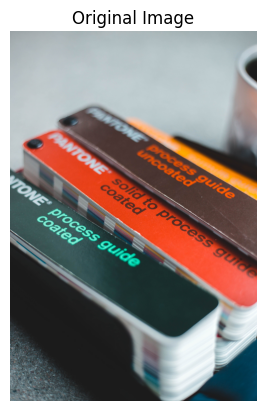

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load image
img = cv2.imread('sample.jpg')   # replace with your image file
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis('off')
plt.show()

rows, cols = img.shape[:2]

## Translation
Shifting the image along the x or y axis.

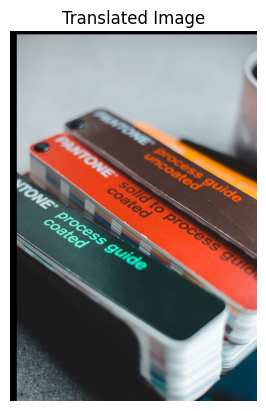

In [3]:
M = np.float32([[1,0,100],[0,1,50]])  # shift right 100px, down 50px
translated = cv2.warpAffine(img, M, (cols, rows))

plt.imshow(cv2.cvtColor(translated, cv2.COLOR_BGR2RGB))
plt.title("Translated Image")
plt.axis('off')
plt.show()

## Scaling (Resizing)
Resizing the image by a factor.

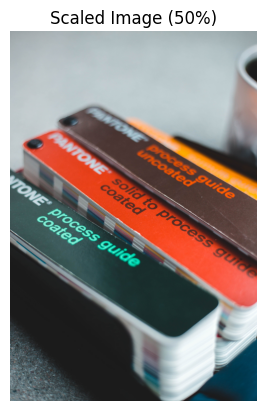

In [4]:
scaled = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_LINEAR)

plt.imshow(cv2.cvtColor(scaled, cv2.COLOR_BGR2RGB))
plt.title("Scaled Image (50%)")
plt.axis('off')
plt.show()

## Rotation
Rotating the image around its center.

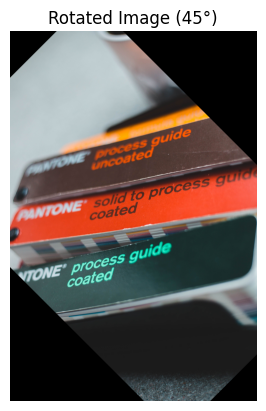

In [5]:
M = cv2.getRotationMatrix2D((cols/2, rows/2), 45, 1)  # rotate 45 degrees
rotated = cv2.warpAffine(img, M, (cols, rows))

plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
plt.title("Rotated Image (45°)")
plt.axis('off')
plt.show()

## Affine Transformation
Preserves parallelism of lines, defined by mapping three points.

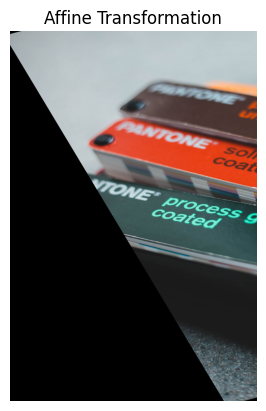

In [6]:
pts1 = np.float32([[50,50],[200,50],[50,200]])
pts2 = np.float32([[10,100],[200,50],[100,250]])
M = cv2.getAffineTransform(pts1, pts2)
affine = cv2.warpAffine(img, M, (cols, rows))

plt.imshow(cv2.cvtColor(affine, cv2.COLOR_BGR2RGB))
plt.title("Affine Transformation")
plt.axis('off')
plt.show()

## Perspective Transformation
Maps a quadrilateral to another quadrilateral. Useful for document scanning.

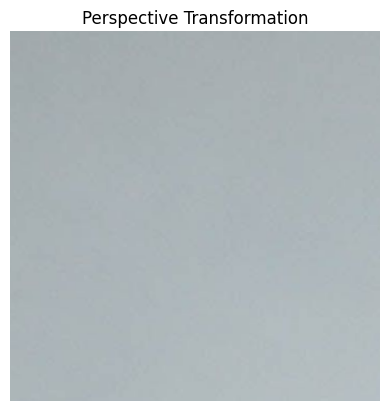

In [7]:
pts1 = np.float32([[56,65],[368,52],[28,387],[389,390]])
pts2 = np.float32([[0,0],[300,0],[0,300],[300,300]])
M = cv2.getPerspectiveTransform(pts1, pts2)
perspective = cv2.warpPerspective(img, M, (300,300))

plt.imshow(cv2.cvtColor(perspective, cv2.COLOR_BGR2RGB))
plt.title("Perspective Transformation")
plt.axis('off')
plt.show()

## Mini‑Project: Image Augmentation Tool
Build a simple tool that applies transformations:
- Translate
- Scale
- Rotate
- Perspective

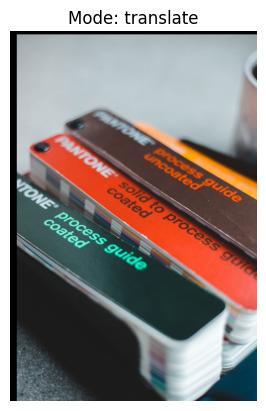

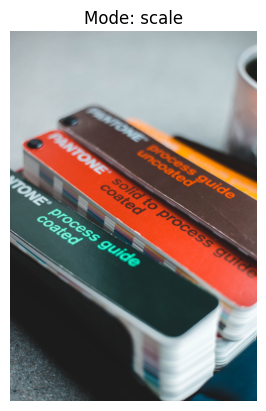

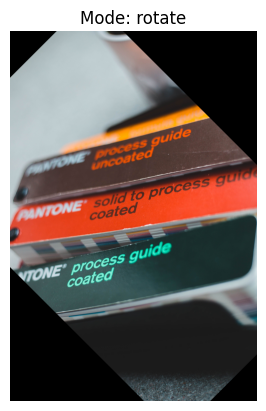

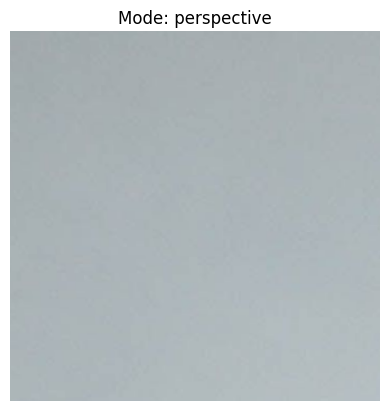

In [8]:
def transform_image(img_path, mode="original"):
    img = cv2.imread(img_path)
    rows, cols = img.shape[:2]
    
    if mode == "translate":
        M = np.float32([[1,0,100],[0,1,50]])
        img = cv2.warpAffine(img, M, (cols, rows))
    elif mode == "scale":
        img = cv2.resize(img, None, fx=0.5, fy=0.5)
    elif mode == "rotate":
        M = cv2.getRotationMatrix2D((cols/2, rows/2), 45, 1)
        img = cv2.warpAffine(img, M, (cols, rows))
    elif mode == "perspective":
        pts1 = np.float32([[56,65],[368,52],[28,387],[389,390]])
        pts2 = np.float32([[0,0],[300,0],[0,300],[300,300]])
        M = cv2.getPerspectiveTransform(pts1, pts2)
        img = cv2.warpPerspective(img, M, (300,300))
    
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Mode: {mode}")
    plt.axis('off')
    plt.show()

# Try different modes
transform_image('sample.jpg', mode="translate")
transform_image('sample.jpg', mode="scale")
transform_image('sample.jpg', mode="rotate")
transform_image('sample.jpg', mode="perspective")